In [1]:
#Basic packages
import os
import sqlite3
from math import ceil

#Pandas, Matplotlib, Seaborn, Scikit-Learn 
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# for better resolution plots
%config InlineBackend.figure_format = 'retina' 

sns.set_theme(palette="Set2")
plt.rcParams["font.family"] = "Arial"

# Functions

def classificar_simetria(skew):
    if skew > 1 or skew < -1:
        return "Highly assymetrical"
    elif skew > 0.5 or skew < -0.5:
        return "Moderately assymetrical"
    else:
        return "Approximately symetrical"

from sklearn.impute import KNNImputer

In [2]:
my_path = Path("acdc_dataset.csv")

# Inspect the raw CSV structure to identify the delimiter

with open(my_path, encoding="utf-8", errors="replace") as f:
    for i, ligne in enumerate(f):
        if i < 10 or 138 <= i <= 142:
            print(i + 1, repr(ligne))

1 'member_id;age;gender;industry;country;is_team_account;n_colleagues_on_account;plan_tier;plan_days_per_week;membership_start;membership_end;last_badge_swipe;days_since_last_visit;total_visits;avg_weekly_visits;entitled_visits_last_period;actual_visits_last_period;meeting_room_hours;event_space_hours;guest_passes_issued;uses_meeting_rooms;uses_event_space;uses_guest_passes;uses_print;uses_mail_handling;uses_phone_booths;uses_day_passes;uses_storage;uses_bike_locker;n_renewals;lifetime_value\n'
2 'CW000001;38.0;Female;Information Technology;Portugal;False;0;flex;3;2021-08-01;2023-03-06;2023-03-23;-17;220;2.65;26.09;22;0.0;0.0;18.0;False;False;True;0;False;True;True;False;False;2;4477.97\n'
3 'CW000002;38.0;Male;Information Technology;Portugal;True;2;HOT_DESK;2;2023-11-24;1970-01-01;2023-11-24;37;2;0.32;10.68;1;0.0;0.0;0.0;False;False;False;0;True;False;False;False;False;0;165.86\n'
4 'CW000003;43.0;Male;Education;DE;True;1;flex;3;2021-12-03;1970-01-01;2023-07-22;163;19;0.17;26.09;2;0.0

In [3]:
# Load the dataset using the identified semicolon delimiter
df = pd.read_csv(my_path, sep=";")

In [4]:
# Check data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

In [5]:
#lifetime_value: df.info() showed that this column is object (text), when it should be a number 

# Try to convert lifetime_value to numbers (values that fail become NaN)
lv_numeric = pd.to_numeric(df["lifetime_value"], errors="coerce")

# Keep only the rows that were NOT empty before but failed the conversion
problems = df[lv_numeric.isna() & df["lifetime_value"].notna()]

# How many problematic values?
print(len(problems))

# Look at some examples
problems["lifetime_value"].head(10)

401


70     246.10 €
83     446.70 €
139    4,311.15
211    859.65 €
220    843.67 €
240    646.66 €
323    485.65 €
359      0.00 €
385    769.55 €
402    193.93 €
Name: lifetime_value, dtype: str

In [6]:
# Force everything to text, then remove the "€" symbol, the commas and the spaces
df["lifetime_value"] = df["lifetime_value"].astype(str)
df["lifetime_value"] = df["lifetime_value"].str.replace("€", "", regex=False)
df["lifetime_value"] = df["lifetime_value"].str.replace(",", "", regex=False)
df["lifetime_value"] = df["lifetime_value"].str.strip()

# Convert to numbers (the text "nan" becomes a real missing value)
df["lifetime_value"] = pd.to_numeric(df["lifetime_value"], errors="coerce")

In [7]:
# The type
print(df["lifetime_value"].dtype)

float64


In [8]:
# uses_print is stored as 0/1, while the other uses_* columns are True/False
print(df["uses_print"].value_counts())

# Convert to boolean, like the other add-on flags
df["uses_print"] = df["uses_print"].astype(bool)
df["uses_print"].dtype

uses_print
0    10469
1     4996
Name: count, dtype: int64


dtype('bool')

In [9]:
# Convert the date columns to real dates (two formats exist: YYYY-MM-DD and DD/MM/YYYY)
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]

for col in date_cols:
    d1 = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
    d2 = pd.to_datetime(df[col], format="%d/%m/%Y", errors="coerce")
    df[col] = d1.fillna(d2)

### Date columns

`membership_start`, `membership_end` and `last_badge_swipe` were stored as object (text).
They were converted to datetime. The dates came in two formats (YYYY-MM-DD and DD/MM/YYYY), both were handled.
No dates were lost during the conversion.

`membership_end` contains the placeholder date 1970-01-01 for 3,956 members (about 26%) before the duplicates are removed (3,954 after).
This is probably a default value for members without an end date (still active), to be treated later.

In [10]:
# The types should be datetime64[ns], not object
df[["membership_start", "membership_end", "last_badge_swipe"]].dtypes

membership_start    datetime64[us]
membership_end      datetime64[us]
last_badge_swipe    datetime64[us]
dtype: object

In [11]:
# No date should have been lost: all three should be 0
df[["membership_start", "membership_end", "last_badge_swipe"]].isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

### Duplicates

15 duplicated observations were found (identical rows with the same `member_id`).
They were removed, leaving 15,450 unique members.

In [12]:
# duplicated observations
df.duplicated().sum()  #15 duplicated

np.int64(15)

In [13]:
# Remove duplicated observations (keeps the first occurrence)
df = df.drop_duplicates()

# Check that no duplicated rows remain
df.duplicated().sum()     

np.int64(0)

In [14]:
# Check the new dimensions 15465 -> 15450
df.shape   

(15450, 31)

In [15]:
# Check that each member appears only once
df["member_id"].duplicated().sum()   

np.int64(0)

## Categorical variables

Before analyzing the categorical variables (`gender`, `country`, `plan_tier`, `industry`), 
we check that each category is written in only one way. 
If the same value appears with different spellings (for example "Female", "female" and "F"), 
counts and charts will be wrong.

In [16]:
# All distinct values of each categorical column
for col in ["gender", "country", "plan_tier", "industry"]:
    print(df[col].value_counts(dropna=False))
    print()

gender
Female     7405
Male       6166
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

country
Portugal           9950
United Kingdom     1104
Germany             850
Spain               711
France              506
Netherlands         463
Other (Europe)      429
NaN                 429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
DE                   14
UK                   14
Deutschland          13
NL                   13
GB                   12
U.K.                 10
Espana               10
United kingdom        9
FR                    9
ES                    8
España                7
IE                    6
ireland               6
spain                 5
nether

### Inconsistencies found

The following problems were found in the categorical variables:
- Different capitalization of the same value 
- Leading or trailing spaces
- Abbreviations (a single letter instead of the full word)
- Spelling mistakes in some country names
- "Unknown" in `industry`, which is a hidden missing value

These are harmonized below so that each category can be counted correctly.

In [17]:
# Remove spaces and put everything in lower case
df["gender"] = df["gender"].str.strip().str.lower()

# Replace abbreviations by the full word
df["gender"] = df["gender"].replace({"f": "female", "m": "male", "o": "other"})

# Check the result: only a few clean categories should remain
df["gender"].value_counts(dropna=False)

gender
female    7858
male      6565
NaN        530
other      497
Name: count, dtype: int64

In [18]:
# Clean and standardize plan_tier values
df["plan_tier"] = df["plan_tier"].str.strip().str.lower()

df["plan_tier"] = df["plan_tier"].replace({
    "flex": "flex",
    
    "hot_desk": "hot_desk",
    "hot desk": "hot_desk",
    "hotdesk": "hot_desk",
    
    "full_time": "full_time",
    "full time": "full_time",
    "fulltime": "full_time",
    
    "dedicated_desk": "dedicated_desk",
    "dedicated desk": "dedicated_desk",
    "dedicateddesk": "dedicated_desk",
    
    "private_office": "private_office",
    "private office": "private_office",
    "privateoffice": "private_office",
})

df["plan_tier"].value_counts(dropna=False)

plan_tier
flex              5449
hot_desk          5212
full_time         2471
dedicated_desk    1549
private_office     664
NaN                105
Name: count, dtype: int64

In [19]:
# Clean and standardize industry values
df["industry"] = df["industry"].str.strip().str.lower()

df["industry"] = df["industry"].replace({
    "information technology": "information technology",
    "it": "information technology",
    "tech": "information technology",

    "consulting": "consulting",

    "marketing & pr": "marketing & pr",
    "marketing/pr": "marketing & pr",
    "marketing and pr": "marketing & pr",

    "design & creative": "design & creative",
    "design/creative": "design & creative",
    "design and creative": "design & creative",

    "finance": "finance",

    "other": "other",

    "legal": "legal",

    "education": "education",

    "unknown": "unknown",

    "health": "health",

    "real estate": "real estate",
    "realestate": "real estate",
    "real-estate": "real estate",
})

# Check the result
df["industry"].value_counts(dropna=False)

industry
information technology    3557
consulting                2055
design & creative         1974
marketing & pr            1962
finance                   1219
other                     1175
legal                      878
education                  775
unknown                    693
health                     601
real estate                561
Name: count, dtype: int64

In [20]:
df["country"] = df["country"].str.strip().str.lower()

df["country"] = df["country"].replace({
    "portucal": "portugal",
    "pt": "portugal",
    "de": "germany",
    "deutschland": "germany",
    "uk": "united kingdom",
    "gb": "united kingdom",
    "u.k.": "united kingdom",
    "nl": "netherlands",
    "the netherlands": "netherlands",
    "holland": "netherlands",
    "fr": "france",
    "es": "spain",
    "espana": "spain",
    "españa": "spain",
    "ie": "ireland",
})

# Check the result
df["country"].value_counts(dropna=False)

country
portugal          10499
united kingdom     1165
germany             901
spain               741
france              533
netherlands         487
other (europe)      451
NaN                 429
ireland             244
Name: count, dtype: int64

In [21]:
df_original = df.copy()

## Impossible values

We check for values that cannot be true (for example negative counts or ages that aren't realistic). 
These are data errors, different from outliers (extreme but possible values).

In [22]:
# Numeric columns that can never be negative (counts, hours, days)
count_cols = ["n_colleagues_on_account", "days_since_last_visit", "total_visits",
              "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
              "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals"]

# Number of negative values in each column
(df[count_cols] < 0).sum()

n_colleagues_on_account        565
days_since_last_visit           56
total_visits                    42
avg_weekly_visits                0
entitled_visits_last_period      0
actual_visits_last_period        0
meeting_room_hours              16
event_space_hours                8
guest_passes_issued              7
n_renewals                      66
dtype: int64

In [23]:
# Range of the age
print(df["age"].min(), df["age"].max())

# Number of members younger than 16 and older than 90
print((df["age"] < 16).sum())
print((df["age"] > 90).sum())

1.0 149.0
98
49


In [24]:
# A week has 7 days: count the values above 7 and equal to 0
print((df["plan_days_per_week"] > 7).sum())
print((df["plan_days_per_week"] == 0).sum())

54
43


In [25]:
# Values that are logically impossible or suspicious
print("plan_days_per_week above 7 (a week has 7 days):", (df["plan_days_per_week"] > 7).sum())
print("avg_weekly_visits above 7 (more than one visit per day on average):", (df["avg_weekly_visits"] > 7).sum())
print("total_visits above 1,213 (more visits than days in the data):", (df["total_visits"] > 1213).sum()) #1213 because it is the number of days between the earliest date in the data (6 September 2020) and the extraction date (1 January 2024)
print("actual visits above entitled visits:", (df["actual_visits_last_period"] > df["entitled_visits_last_period"]).sum())

plan_days_per_week above 7 (a week has 7 days): 54
avg_weekly_visits above 7 (more than one visit per day on average): 42
total_visits above 1,213 (more visits than days in the data): 7
actual visits above entitled visits: 8


In [26]:
# Placeholder date in membership_end
is_placeholder = df["membership_end"] == pd.Timestamp("1970-01-01")
print("Members with the placeholder date 1970-01-01:", is_placeholder.sum(),
      f"({is_placeholder.mean() * 100:.1f}%)")

# Among the real end dates (placeholder excluded)
real_end = df[~is_placeholder]
print("End date before start date:", (real_end["membership_end"] < real_end["membership_start"]).sum())
print("Last badge swipe after end date:", (real_end["last_badge_swipe"] > real_end["membership_end"]).sum())

# End dates before the first membership of the company
print("End date before the first membership start:",
      (df["membership_end"] < df["membership_start"].min()).sum())

Members with the placeholder date 1970-01-01: 3954 (25.6%)
End date before start date: 152
Last badge swipe after end date: 213
End date before the first membership start: 3969


In [27]:
#Badge swipes before membership start
invalid_swipes = (
    df["last_badge_swipe"] < df["membership_start"]
)

print("Badge swipes before membership start:", invalid_swipes.sum())

Badge swipes before membership start: 94


In [28]:
# Hours recorded although the member is flagged as not using meeting rooms
print(((df["meeting_room_hours"] > 0) & (~df["uses_meeting_rooms"])).sum())

# Flagged as using meeting rooms although the hours are zero
print(((df["meeting_room_hours"] == 0) & (df["uses_meeting_rooms"])).sum())

55
7


In [29]:
# Extraction date: last_badge_swipe + days_since_last_visit should give the same date for everybody
implied = (df["last_badge_swipe"] + pd.to_timedelta(df["days_since_last_visit"], unit="D")).dt.normalize()
print("Most common implied extraction dates:")
print(implied.value_counts().head(3))

Most common implied extraction dates:
2024-01-01    3383
2023-12-31     263
2023-11-28      29
Name: count, dtype: int64


,n_missing,pct_missing
meeting_room_hours,1295,8.4
guest_passes_issued,1269,8.2
lifetime_value,1040,6.7
age,557,3.6
gender,530,3.4
country,429,2.8
plan_tier,105,0.7


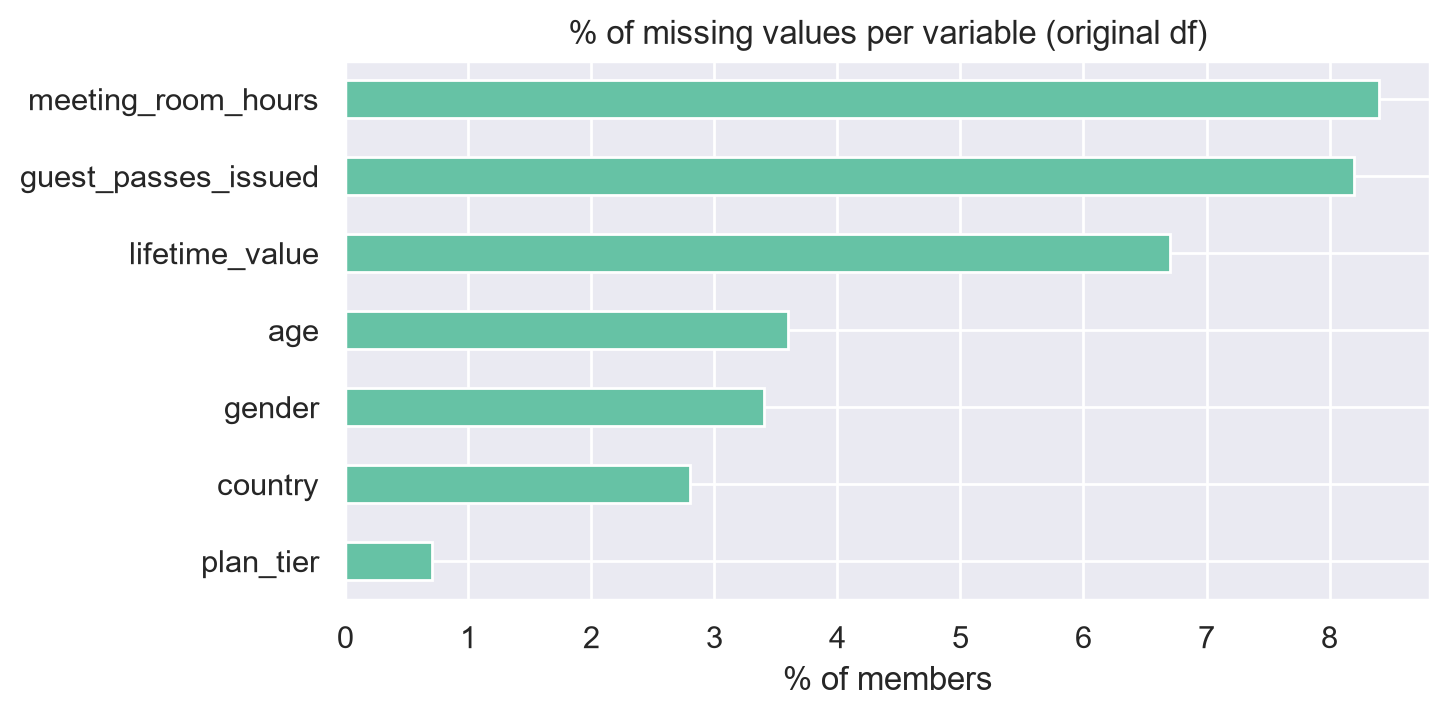

,variable,by,lowest_%,highest_%
0,meeting_room_hours,plan_tier,1.7,11.7
1,meeting_room_hours,is_team_account,8.2,8.9
2,meeting_room_hours,start year,7.7,9.7
3,guest_passes_issued,plan_tier,2.3,10.8
4,guest_passes_issued,is_team_account,7.9,8.4
5,guest_passes_issued,start year,7.6,9.0
6,lifetime_value,plan_tier,4.7,10.8
7,lifetime_value,is_team_account,6.5,7.3
8,lifetime_value,start year,3.7,7.9
9,age,plan_tier,3.0,4.2


meeting_room_hours missing vs. uses_meeting_rooms


uses_meeting_rooms,False,True
hours missing,,
False,9290,4865
True,902,393


guest_passes_issued missing vs. uses_guest_passes


uses_guest_passes,False,True
passes missing,,
False,11573,2608
True,1066,203


meeting_room_hours and guest_passes_issued missing together?


passes missing,False,True
hours missing,,
False,13045,1110
True,1136,159


Number of missing values per member (original variables):


0    11086
1     3581
2      705
3       78
Name: count, dtype: int64

,n_members,pct
industry == 'unknown',693,4.5
n_colleagues_on_account == -1,565,3.7
days_since_last_visit >= 999 (possible code),1304,8.4
membership_end == 1970-01-01 (no end date),3954,25.6
lifetime_value == 0,1742,11.3


In [30]:
orig = df.copy()

# How many values are missing in each original variable?
miss = pd.DataFrame({"n_missing": orig.isna().sum()})
miss["pct_missing"] = (miss["n_missing"] / len(orig) * 100).round(1)
miss = miss[miss["n_missing"] > 0].sort_values("n_missing", ascending=False)
display(miss)

miss["pct_missing"].sort_values().plot(kind="barh", figsize=(7, 3.5))
plt.title("% of missing values per variable (original df)")
plt.xlabel("% of members")
plt.show()

# Do the members with a missing value have something in common? (lowest and highest % missing across the groups)
rows = []
for v in miss.index:
    flag = df[v].isna()
    for g in ["plan_tier", "is_team_account"]:
        rate = flag.groupby(df[g]).mean() * 100
        rows.append({"variable": v, "by": g, "lowest_%": rate.min(), "highest_%": rate.max()})
    rate = flag.groupby(df["membership_start"].dt.year).mean() * 100
    rows.append({"variable": v, "by": "start year", "lowest_%": rate.min(), "highest_%": rate.max()})
display(pd.DataFrame(rows).round(1))

# Link with the yes/no variables of the same service
print("meeting_room_hours missing vs. uses_meeting_rooms")
display(pd.crosstab(df["meeting_room_hours"].isna(), df["uses_meeting_rooms"], dropna=False,
                    rownames=["hours missing"], colnames=["uses_meeting_rooms"]))
print("guest_passes_issued missing vs. uses_guest_passes")
display(pd.crosstab(df["guest_passes_issued"].isna(), df["uses_guest_passes"], dropna=False,
                    rownames=["passes missing"], colnames=["uses_guest_passes"]))

# Are values missing together in the same members?
print("meeting_room_hours and guest_passes_issued missing together?")
display(pd.crosstab(df["meeting_room_hours"].isna(), df["guest_passes_issued"].isna(),
                    rownames=["hours missing"], colnames=["passes missing"]))
print("Number of missing values per member (original variables):")
display(orig.isna().sum(axis=1).value_counts().sort_index())

# Hidden missing values: codes written as normal values
hidden_codes = pd.Series({
    "industry == 'unknown'": (df["industry"] == "unknown").sum(),
    "n_colleagues_on_account == -1": (df["n_colleagues_on_account"] == -1).sum(),
    "days_since_last_visit >= 999 (possible code)": (df["days_since_last_visit"] >= 999).sum(),
    "membership_end == 1970-01-01 (no end date)": (df["membership_end"] == pd.Timestamp("1970-01-01")).sum(),
    "lifetime_value == 0": (df["lifetime_value"] == 0).sum(),
})
pd.DataFrame({"n_members": hidden_codes, "pct": (hidden_codes / len(df) * 100).round(1)})

### Missing values: conclusions
- `meeting_room_hours` (8.4%), `guest_passes_issued` (8.2%) and `lifetime_value` (6.7%) have the most missing values.
- The missing rates change between plans (for example 1.7% to 11.7% for `meeting_room_hours`), so the values aren't missing completely at random (MCAR). Missing at random (MAR) is a plausible assumption.
- Some missing hours belong to members who don't use the service, so their real value is 0.
- On top of these, some missing values were hidden as codes (1970-01-01, 999, -1), which are set to missing below.

**Decision:** members who don't use a service get 0; the other metric values are imputed with the median (the variables are very skewed, so the median and not the mean) and the non-metric values with the mode. `days_since_last_visit` is imputed with the KNN imputer.

In [31]:
# Membership status (before touching the dates) 
# 01/01/1970 is the placeholder for "no end date"; we assume these members are still active (to be confirmed)
df["is_active"] = df["membership_end"].dt.year == 1970
df.loc[df["is_active"], "membership_end"] = pd.NaT

# Impossible / suspicious values -> missing
nonneg_cols = ["n_colleagues_on_account", "days_since_last_visit", "total_visits", "avg_weekly_visits",
               "entitled_visits_last_period", "actual_visits_last_period", "meeting_room_hours",
               "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
for col in nonneg_cols:
    df.loc[df[col] < 0, col] = np.nan

df.loc[(df["age"] < 16) | (df["age"] > 90), "age"] = np.nan
df.loc[df["plan_days_per_week"] > 7, "plan_days_per_week"] = np.nan
df.loc[df["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan
df.loc[df["total_visits"] > 1213, "total_visits"] = np.nan
# days_since_last_visit around 999 is a code for "no visit recorded", not a real number of days
df.loc[df["days_since_last_visit"] >= 999, "days_since_last_visit"] = np.nan

In [32]:
ref_date = implied.mode().iloc[0] if implied.notna().any() else df["last_badge_swipe"].max()
print("Reference date used:", ref_date.date())

# Tenure: to the end date, or to the extraction date for the active members
end_or_ref = df["membership_end"].where(~df["is_active"], ref_date)
df["tenure_months"] = (end_or_ref - df["membership_start"]).dt.days / 30.44
df.loc[df["tenure_months"] < 0, "tenure_months"] = np.nan      # end date before start date

# Utilisation: actual visits / entitled visits in the last period
df["utilisation"] = np.where(df["entitled_visits_last_period"] > 0,
                             df["actual_visits_last_period"] / df["entitled_visits_last_period"], np.nan)

# Number of add-ons used
addon_cols = ["uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print", "uses_mail_handling",
              "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker"]
df["n_addons"] = df[addon_cols].fillna(False).astype(bool).sum(axis=1)

df[["tenure_months", "utilisation", "n_addons"]].describe().T.round(2)

Reference date used: 2024-01-01


,count,mean,std,min,25%,50%,75%,max
tenure_months,15298.0,12.31,11.13,0.07,2.14,9.28,20.93,35.97
utilisation,15440.0,0.52,0.31,0.00,0.24,0.52,0.80,1.00
n_addons,15450.0,1.82,1.50,0.00,1.00,1.00,3.00,8.00


In [33]:
non_metric_features = ["member_id", "gender", "industry", "country", "plan_tier",
                       "is_team_account", "uses_meeting_rooms", "uses_event_space",
                       "uses_guest_passes", "uses_print", "uses_mail_handling",
                       "uses_phone_booths", "uses_day_passes", "uses_storage",
                       "uses_bike_locker", "is_active"]
date_features = ["membership_start", "membership_end", "last_badge_swipe"]
metric_features = df.columns.drop(non_metric_features + date_features).to_list()
metric_features

['age',
 'n_colleagues_on_account',
 'plan_days_per_week',
 'days_since_last_visit',
 'total_visits',
 'avg_weekly_visits',
 'entitled_visits_last_period',
 'actual_visits_last_period',
 'meeting_room_hours',
 'event_space_hours',
 'guest_passes_issued',
 'n_renewals',
 'lifetime_value',
 'tenure_months',
 'utilisation',
 'n_addons']

## Missing values

### Services not used
If a member doesn't use a service, a missing number of hours or passes means 0. When hours are recorded but the flag says the service isn't used (55 members), we trust the hours and correct the flag.

In [34]:
# Hours recorded although the flag says the member doesn't use meeting rooms: correct the flag
df.loc[(df["meeting_room_hours"] > 0) & (~df["uses_meeting_rooms"]), "uses_meeting_rooms"] = True

# Members who don't use the service: the missing value is 0
df.loc[df["meeting_room_hours"].isna() & (~df["uses_meeting_rooms"]), "meeting_room_hours"] = 0
df.loc[df["guest_passes_issued"].isna() & (~df["uses_guest_passes"]), "guest_passes_issued"] = 0

# n_addons is computed from the flags, so it is recomputed after the correction
df["n_addons"] = df[addon_cols].sum(axis=1)

# count of missing values (membership_end is missing on purpose for the active members, it isn't imputed)
df.isna().sum()

member_id                         0
age                             704
gender                          530
industry                          0
country                         429
is_team_account                   0
n_colleagues_on_account         565
plan_tier                       105
plan_days_per_week               54
membership_start                  0
membership_end                 3954
last_badge_swipe                  0
days_since_last_visit          1360
total_visits                     49
avg_weekly_visits                42
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours              409
event_space_hours                 8
guest_passes_issued             210
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

### Measures of central tendency
Mean or median?

In [35]:
# Creating a copy to apply central tendency measures imputation
df_central = df.copy()

means = df[metric_features].mean()
medians = df[metric_features].median()

pd.DataFrame({"mean": means, "median": medians, "skew": df[metric_features].skew()}).round(2)

,mean,median,skew
age,34.73,34.00,0.36
n_colleagues_on_account,0.60,0.00,2.24
plan_days_per_week,3.37,3.00,0.83
days_since_last_visit,36.86,10.00,3.66
total_visits,109.30,35.00,2.14
avg_weekly_visits,1.71,1.42,0.92
entitled_visits_last_period,27.51,26.09,0.73
actual_visits_last_period,13.80,10.00,1.06
meeting_room_hours,31.16,0.00,72.96
event_space_hours,5.12,0.00,9.22


Most variables are very skewed, so the mean is pulled by the extreme values and is far from the median. We use the median for the metric features and the mode for the non-metric features.

In [36]:
modes = df_central[non_metric_features].mode().loc[0]

# Fill NaNs on df_central
df_central[metric_features] = df_central[metric_features].fillna(medians)
df_central[non_metric_features] = df_central[non_metric_features].fillna(modes)

df_central[metric_features + non_metric_features].isna().sum()

age                            0
n_colleagues_on_account        0
plan_days_per_week             0
days_since_last_visit          0
total_visits                   0
avg_weekly_visits              0
entitled_visits_last_period    0
actual_visits_last_period      0
meeting_room_hours             0
event_space_hours              0
guest_passes_issued            0
n_renewals                     0
lifetime_value                 0
tenure_months                  0
utilisation                    0
n_addons                       0
member_id                      0
gender                         0
industry                       0
country                        0
plan_tier                      0
is_team_account                0
uses_meeting_rooms             0
uses_event_space               0
uses_guest_passes              0
uses_print                     0
uses_mail_handling             0
uses_phone_booths              0
uses_day_passes                0
uses_storage                   0
uses_bike_

### KNN imputer
1,360 members have no valid `days_since_last_visit` (mostly the code 999, plus 56 negative values). With the median, all of them would get the same value (10 days), as if they had visited recently. The KNN imputer uses the members with the most similar visit behavior instead. 

In [37]:
# Creating new df copy to explore neighborhood imputation
df_neighbors = df.copy()

# Rows with NaNs in days_since_last_visit
nans_index = df_neighbors["days_since_last_visit"].isna()
print("Missing days_since_last_visit:", nans_index.sum())

Missing days_since_last_visit: 1360


In [38]:
# KNNImputer (only works for numerical variables)
# days_since_last_visit is filled with the 5 members with the most similar visits
visit_cols = ["days_since_last_visit", "avg_weekly_visits", "actual_visits_last_period", "utilisation"]
imputer = KNNImputer(n_neighbors=5, weights="uniform")
df_neighbors[visit_cols] = imputer.fit_transform(df_neighbors[visit_cols])

In [39]:
# Compare the two imputations for the members that had no visit recorded
pd.DataFrame({
    "median imputation": df_central.loc[nans_index, "days_since_last_visit"].describe(),
    "KNN imputation": df_neighbors.loc[nans_index, "days_since_last_visit"].describe(),
}).round(1)

,median imputation,KNN imputation
count,1360.0,1360.0
mean,10.0,52.8
std,0.0,68.5
min,10.0,1.4
25%,10.0,7.6
50%,10.0,30.0
75%,10.0,49.2
max,10.0,355.6


#### Keep central tendency imputation, with KNN for `days_since_last_visit`
The median works for most variables, but it gives the same value (10 days) to all 1,360 members without a valid value. KNN gives them values based on similar members (median of 30 days, from 1 to 356), so they keep their differences.

In [40]:
# Keep the central imputation, and take days_since_last_visit from the KNN imputation
df = df_central.copy()
df["days_since_last_visit"] = df_neighbors["days_since_last_visit"]

# No missing values should remain in the features
df[metric_features + non_metric_features].isna().sum().sum()

np.int64(0)

## Outlier removal

### Outlier removal using only the IQR method

In [41]:
# Calculate Q1, Q3, IQR
q1 = df[metric_features].quantile(0.25)
q3 = df[metric_features].quantile(0.75)
iqr = q3 - q1

# Compute upper and lower limit
lower_lim = q1 - (iqr * 1.5)
upper_lim = q3 + (iqr * 1.5)

pd.DataFrame({"lower_lim": lower_lim, "upper_lim": upper_lim}).round(2)

,lower_lim,upper_lim
age,12.50,56.50
n_colleagues_on_account,-1.50,2.50
plan_days_per_week,-2.50,9.50
days_since_last_visit,-54.50,101.50
total_visits,-178.00,318.00
avg_weekly_visits,-1.83,4.94
entitled_visits_last_period,-21.74,82.61
actual_visits_last_period,-17.50,42.50
meeting_room_hours,-5.85,9.75
event_space_hours,0.00,0.00


In [42]:
# inclusive="both" keeps the values equal to the limits (for example the zeros of the services)
filters_iqr_all = df[metric_features].apply(
    lambda col: col.between(lower_lim[col.name], upper_lim[col.name], inclusive="both")
).all(axis=1)

df_iqr = df[filters_iqr_all]
print("Percentage of data kept after removing outliers:", 100 * np.round(df_iqr.shape[0] / df_original.shape[0], 4))

Percentage of data kept after removing outliers: 48.54


The IQR method keeps only 48.54% of the members, far below the rule of thumb (remove at most 5%). Many variables are mostly zeros (`meeting_room_hours`, `event_space_hours`, `guest_passes_issued`), so their IQR is 0 or very small and almost every member who uses the service becomes an "outlier". The IQR method isn't suitable here, so we filter manually.

### Manual outlier removal
We remove the members with extreme values that appear in every plan, even the cheapest one (D1), so they are most likely errors and not real customers.

In [43]:
filters_man = (
    (df["lifetime_value"] <= 100_000)      # 47 members above 100,000 euros in D1, up to 3.4 million
    &
    (df["meeting_room_hours"] <= 1000)     # up to 41,220 hours in D1
)

df_man = df[filters_man]
print("Members removed:", (~filters_man).sum())
print("Percentage of data kept after removing outliers:", 100 * np.round(df_man.shape[0] / df_original.shape[0], 4))

Members removed: 63
Percentage of data kept after removing outliers: 99.59


In [44]:
## Applying the manual filtering
df = df_man.copy()

### Winsorizing (outlier threshold value)
The remaining variables still have long right tails: very active or very valuable members, which are possible. Instead of removing these members, we cap their values at the 99th percentile, so that a few members don't dominate the distances in the clustering.

In [45]:
winsor_cols = ["total_visits", "meeting_room_hours", "event_space_hours",
               "guest_passes_issued", "lifetime_value"]

for col in winsor_cols:
    upper = df[col].quantile(0.99)
    print(col, "capped at", round(upper, 2), "-", (df[col] > upper).sum(), "members")
    df.loc[df[col] > upper, col] = upper

total_visits capped at 689.0 - 151 members
meeting_room_hours capped at 298.94 - 154 members
event_space_hours capped at 126.49 - 154 members
guest_passes_issued capped at 114.14 - 154 members
lifetime_value capped at 24746.51 - 154 members


### Visualize the boxplots after the outlier treatment

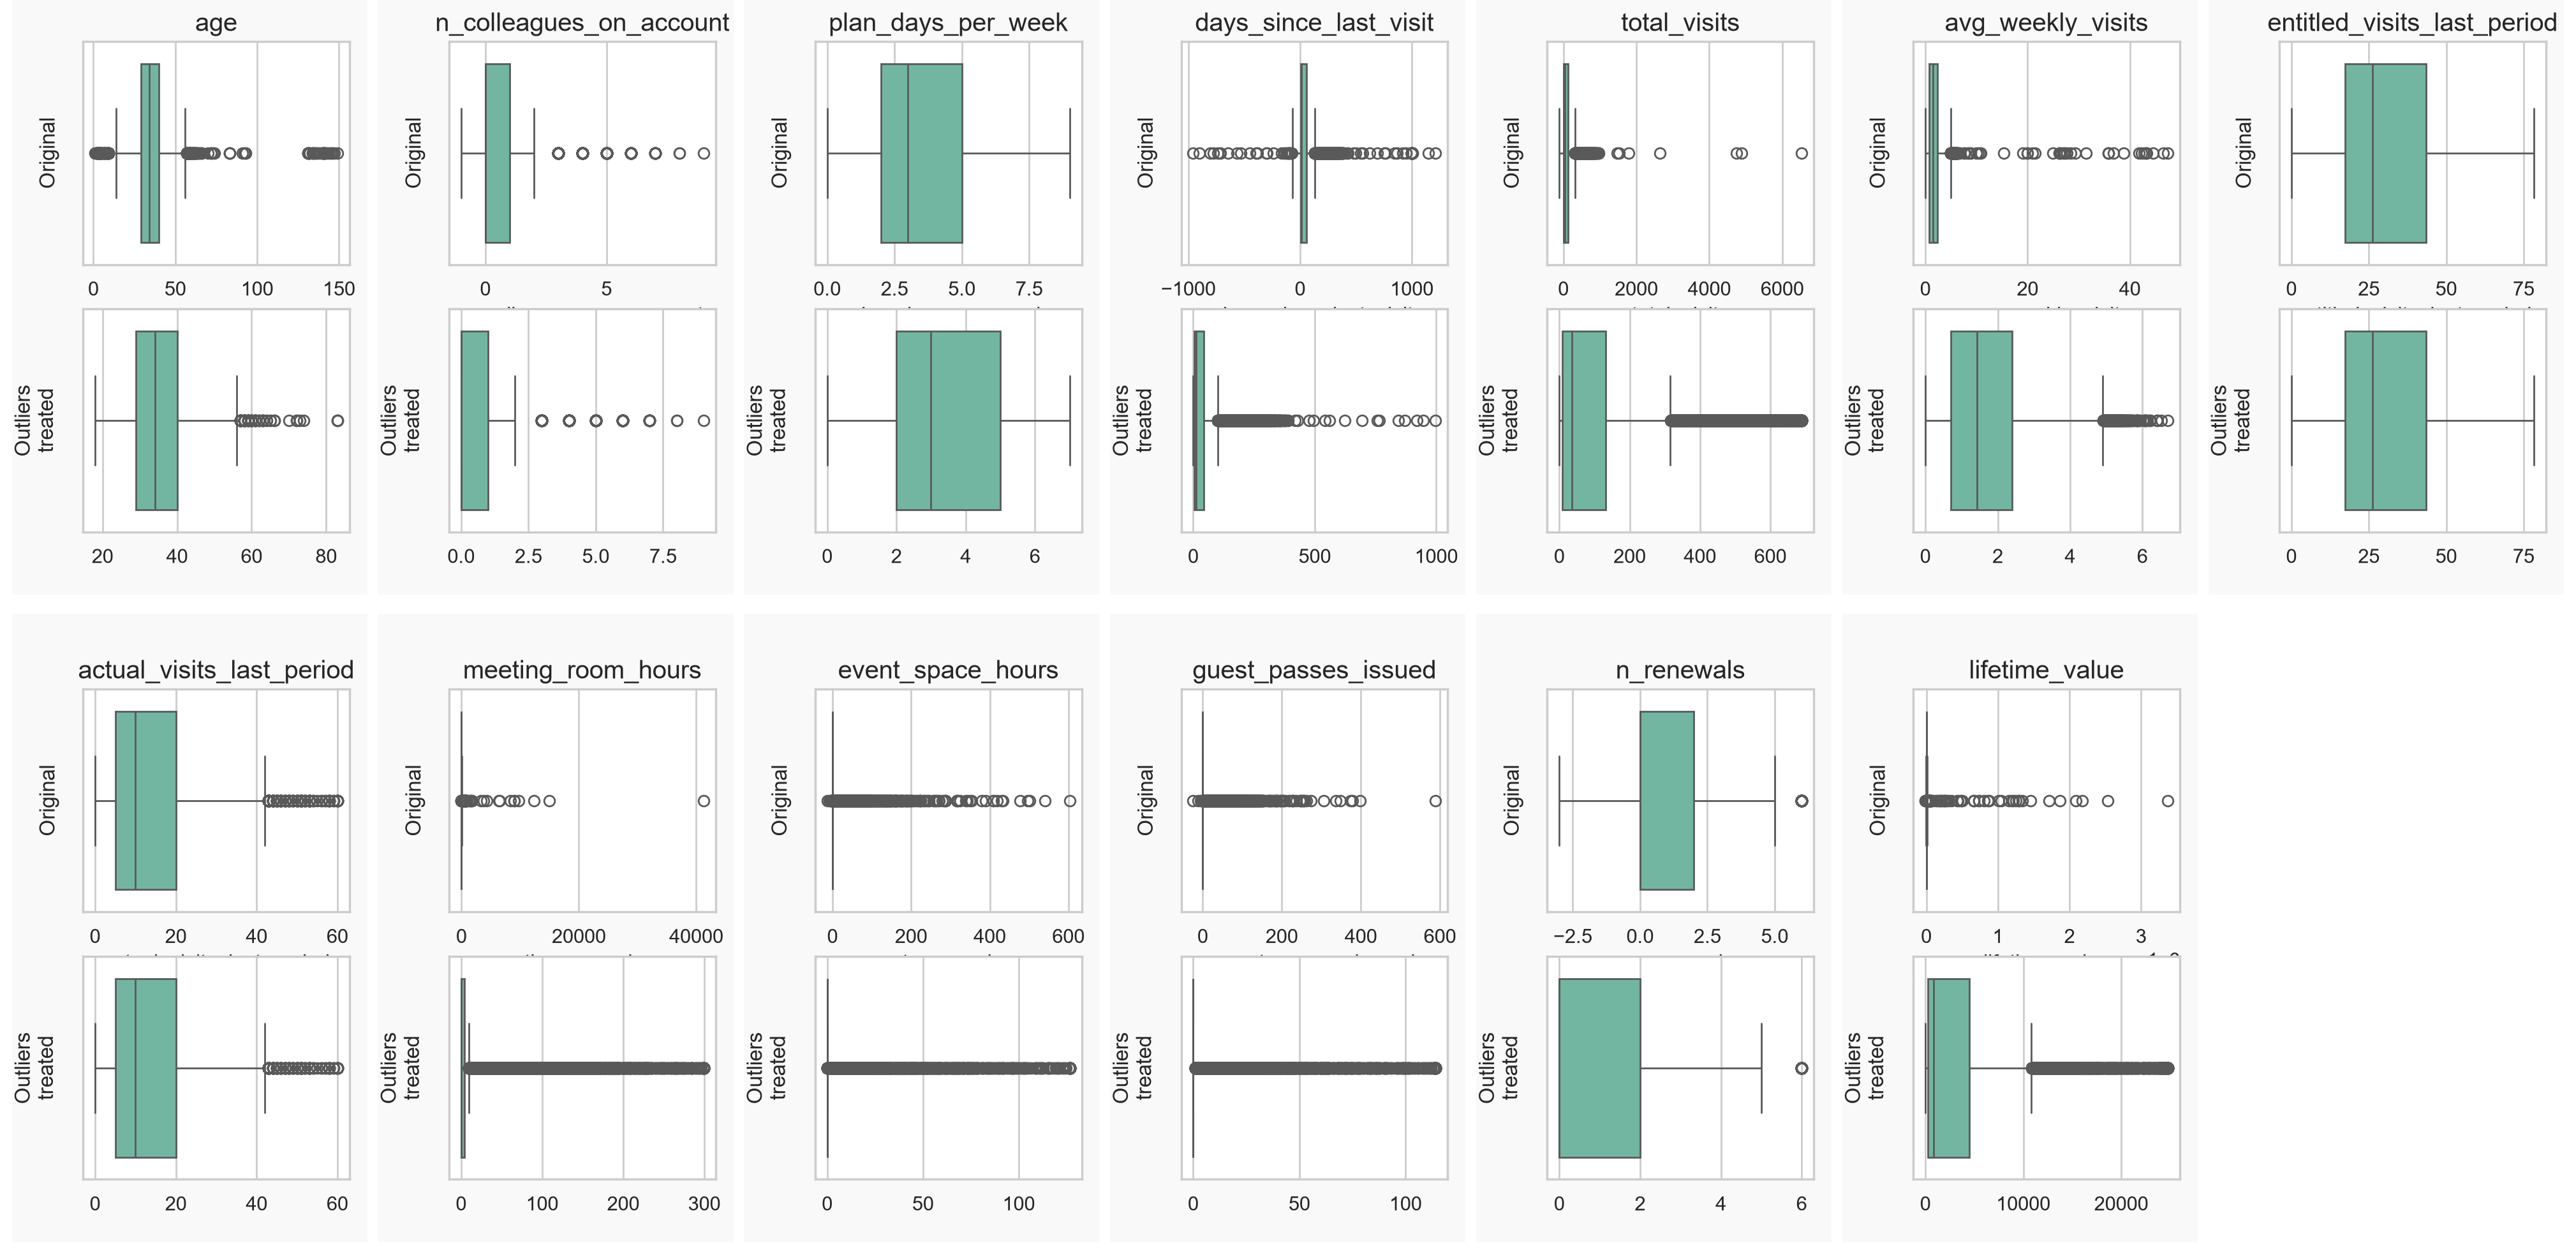

In [46]:
# Only the variables that exist in the original data
compare_features = [f for f in metric_features if f in df_original.columns]

sns.set_style("whitegrid")

fig = plt.figure(figsize=(20, 10))
subfigs = fig.subfigures(
    2,
    ceil(len(compare_features) / 2),
    wspace=.03, hspace=.03)

for sfig, feat in zip(subfigs.flatten(), compare_features):
    axes = sfig.subplots(2, 1, sharex=False)

    sns.boxplot(x=df_original[feat], ax=axes[0])
    axes[0].set_ylabel("Original")
    axes[0].set_title(feat, fontsize="large")

    sns.boxplot(x=df[feat], ax=axes[1])
    axes[1].set_ylabel("Outliers\ntreated")
    axes[1].set_xlabel("")

    # Subfigure Aesthetics
    sfig.set_facecolor("#F9F9F9")
    sfig.subplots_adjust(left=.2, right=.95, bottom=.1)

plt.show()

### Insights
- The IQR method would keep only 48.54% of the members, so we used the manual filter instead: 63 members were removed (`lifetime_value` above 100,000 euros or more than 1,000 meeting room hours), and 99.6% of the members were kept.
- The 99th percentile cap reduced the long tails without removing anyone: for example `meeting_room_hours` now goes up to about 300 hours (41,220 before) and `lifetime_value` up to about 24,750 euros (3.4 million before).
- The services (`meeting_room_hours`, `event_space_hours`, `guest_passes_issued`) still show many points above the whiskers. Most members have 0, so every member who uses the service looks like an outlier in the boxplot; these values are kept.